<a href="https://colab.research.google.com/github/aryananand0/Math-344-Lab-Project-Fall-2026/blob/main/Notebooks/01_ratings_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 1: Ratings as a Matrix

I use a toy example and the MovieLens data to show how movie ratings fit into a matrix.

# Part A

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

These are the three libraries I use in this notebook. NumPy does the matrix math, pandas handles the tables, and matplotlib makes the plots.

In [2]:
# labels for the columns (movies) and rows (users)
movies = ["Die Hard", "Mad Max: Fury Road", "The Terminator",
          "The Notebook", "Pride & Prejudice", "Notting Hill"]
users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]

The first three movies are action and the last three are romance. These lists are just labels for the rows and columns, they aren’t the actual matrix.


In [3]:
# np.nan = the user hasn't rated that movie
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],         # Ana
    [4, np.nan, 5, 2, 1, 1],         # Ben
    [5, 5, np.nan, 1, 2, np.nan],    # Cal
    [1, 2, 1, 5, 4, np.nan],         # Dee
    [np.nan, 1, 2, 4, 5, 5],         # Eve
    [2, 1, np.nan, 5, np.nan, 4],    # Fay
])

# same numbers, but with names on the rows and columns
toy_table = pd.DataFrame(toy, index=users, columns=movies)
toy_table

,Die Hard,Mad Max: Fury Road,The Terminator,The Notebook,Pride & Prejudice,Notting Hill
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0


This is my 6 × 6 toy ratings matrix. Each row is a person and each column is a movie. Wrapping it in a DataFrame doesn’t change the numbers, it just shows the names so the table is easier to read.

In [4]:
# True where a rating is missing, then count the Trues
missing = np.isnan(toy).sum()
print("Missing entries:", missing, "out of", toy.size)

Missing entries: 8 out of 36


`np.isnan(toy)` gives a True/False matrix with True wherever a rating is missing, and `.sum()` counts the Trues since True counts as 1. I counted 8 missing ratings out of 36.

# Part B

In [5]:
import os
import urllib.request
import zipfile

# download if either of the files I read is missing
if not (os.path.exists("ml-100k/u.data") and os.path.exists("ml-100k/u.item")):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    with zipfile.ZipFile("ml-100k.zip") as zipped:
        zipped.extractall()

This downloads and unzips the data, but only if one of the data files is missing, so rerunning the cell doesn’t download it again. The data stays in Colab’s temporary storage and doesn’t go on GitHub because the license doesn’t allow redistributing it.

In [6]:
# file is tab-separated and has no header row
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)
ratings.head()

,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


The file uses tabs between columns, so I use `sep="\t"`. It doesn’t have a header, so I give the columns names. Every row is one rating: who rated, which movie, how many stars, and when.

In [7]:
print("Number of ratings:", len(ratings))              # rows
print("Number of users:", ratings["user"].nunique())   # distinct users
print("Number of movies:", ratings["item"].nunique())  # distinct movies

Number of ratings: 100000
Number of users: 943
Number of movies: 1682


`len` counts the rows and `.nunique()` counts the distinct IDs in a column. The data has 100,000 ratings, 943 users, and 1,682 movies.

In [8]:
# how many times each star value shows up, in order 1 to 5
star_counts = ratings["rating"].value_counts().sort_index()
print(star_counts)

average_rating = ratings["rating"].mean()
print("Average rating:", round(average_rating, 3))

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64
Average rating: 3.53


`value_counts()` counts how often each star rating appears, and `sort_index()` puts them in order. The average rating is about 3.53.

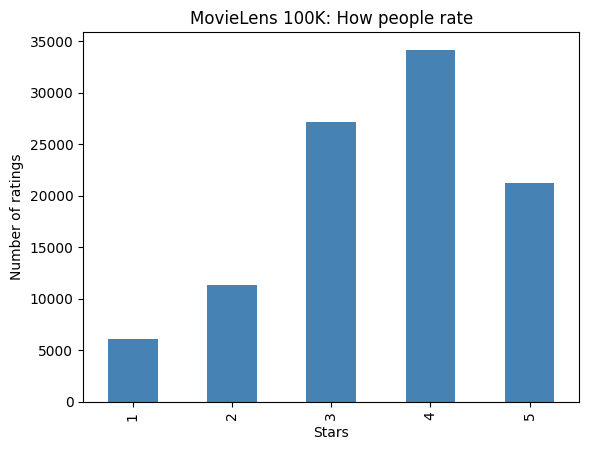

In [9]:
star_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Stars")
plt.ylabel("Number of ratings")
plt.title("MovieLens 100K: How people rate")
plt.show()

The bar chart shows 4 stars is the most common, then 3, and 1 star is the rarest. That makes sense because people mostly pick movies they think they’ll like.

# Part C


In [10]:
# rows = users, columns = movies, entries = star ratings
R = ratings.pivot_table(
    index="user",
    columns="item",
    values="rating"
)

print("Matrix shape:", R.shape)
fraction_missing = R.isna().to_numpy().mean()   # True=1, False=0
print("Fraction missing:", round(fraction_missing, 4))

Matrix shape: (943, 1682)
Fraction missing: 0.937


`pivot_table` rearranges the long list of ratings into a matrix with one row per user and one column per movie, so R[i, j] is user i’s rating of movie j. The shape is (943, 1682), and about 93.7% of the entries are NaN. So most of the matrix is empty.

In [11]:
# number of ratings each user gave
per_user = ratings.groupby("user").size()
print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 20
Median user: 65
Most active user: 737


This counts how many ratings each user gave. The least active rated 20 movies, the median user rated 65, and the most active rated 737. That’s a big spread.

I can’t run `np.linalg.svd` on R yet because it needs every entry to be a number, and R is mostly NaN. Filling in those blanks is basically the whole recommendation problem.

# Part D

In [12]:
# u.item uses | as a separator, latin-1 handles accented titles
titles = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["item", "title"]
)

This file uses `|` between columns, and I use `latin-1` encoding because some titles have accented letters. I only keep the movie ID and title.

In [13]:
# count and average rating per movie, then attach titles
stats = ratings.groupby("item")["rating"].agg(["count", "mean"])
stats = stats.join(titles.set_index("item"))

top_five = stats.sort_values("count", ascending=False).head(5)
top_five.round(2)

,count,mean,title
item,,,
50,583,4.36,Star Wars (1977)
258,509,3.80,Contact (1997)
100,508,4.16,Fargo (1996)
181,507,4.01,Return of the Jedi (1983)
294,485,3.16,Liar Liar (1997)


For each movie I count its ratings and find its average. Then `join` matches up the titles using the movie ID. Sorting by count from biggest to smallest and taking the top 5 shows the most-rated movies, and Star Wars (1977) comes out on top.

# Exercise 1

In [14]:
# (row, column) position of every missing rating
missing_spots = np.argwhere(np.isnan(toy))
for i, j in missing_spots:
    print(users[i], "has not rated", movies[j])

Ana has not rated Pride & Prejudice
Ben has not rated Mad Max: Fury Road
Cal has not rated The Terminator
Cal has not rated Notting Hill
Dee has not rated Notting Hill
Eve has not rated Die Hard
Fay has not rated The Terminator
Fay has not rated Pride & Prejudice


`np.argwhere` returns the position of every missing entry, then I use those positions to look up the person and movie names.

In [15]:
action_fans = [0, 1, 2]    # Ana, Ben, Cal
romance_fans = [3, 4, 5]   # Dee, Eve, Fay

predictions = toy.copy()
for i, j in missing_spots:
    # use the people with the same taste as user i
    group = action_fans if i in action_fans else romance_fans
    predictions[i, j] = np.nanmean(toy[group, j])

pd.DataFrame(predictions, index=users, columns=movies).round(1)

,Die Hard,Mad Max: Fury Road,The Terminator,The Notebook,Pride & Prejudice,Notting Hill
Ana,5.0,4.0,5.0,1.0,1.5,2.0
Ben,4.0,4.5,5.0,2.0,1.0,1.0
Cal,5.0,5.0,5.0,1.0,2.0,1.5
Dee,1.0,2.0,1.0,5.0,4.0,4.5
Eve,1.5,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,1.5,5.0,4.5,4.0


To predict a missing rating, I averaged what the people with similar taste gave that movie. `np.nanmean` ignores NaN values, so the person’s own missing rating doesn’t mess up the average. Here are the 8 predictions:

   | User | Movie | Prediction |
   |---|---|---|
   | Ana | Pride & Prejudice | 1.5 |
   | Ben | Mad Max: Fury Road | 4.5 |
   | Cal | The Terminator | 5 |
   | Cal | Notting Hill | 1.5 |
   | Dee | Notting Hill | 4.5 |
   | Eve | Die Hard | 1.5 |
   | Fay | The Terminator | 1.5 |
   | Fay | Pride & Prejudice | 4.5 |

Justifying two of them: Cal gave Die Hard and Mad Max both 5s, and Ana and Ben (the other action fans) both gave The Terminator a 5, so a 5 for Cal makes sense. Fay gave The Notebook a 5 and Notting Hill a 4, and Dee and Eve rated Pride & Prejudice 4 and 5, so around 4.5 for Fay seems right.

# Exercise 2

In [16]:
# Gus: loves action, hates romance, two missing ratings
gus = np.array([5, 5, np.nan, 1, np.nan, 1])
toy7 = np.vstack([toy, gus])     # add him as a new bottom row
users7 = users + ["Gus"]
pd.DataFrame(toy7, index=users7, columns=movies)

,Die Hard,Mad Max: Fury Road,The Terminator,The Notebook,Pride & Prejudice,Notting Hill
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0
Gus,5.0,5.0,NaN,1.0,NaN,1.0


I added Gus as a new imaginary user. He loves Die Hard and Mad Max and gave both romance movies he saw a 1. `np.vstack` sticks his row onto the bottom of the matrix.

In [17]:
# predict his missing ratings from the other action fans
for j in [2, 4]:
    guess = np.nanmean(toy[action_fans, j])
    print("Gus,", movies[j], "->", round(guess, 1))

Gus, The Terminator -> 5.0
Gus, Pride & Prejudice -> 1.5


Since Gus looks just like Ana, Ben, and Cal, I used their ratings. That gives about 5 for The Terminator and 1.5 for Pride & Prejudice. Honestly I’d probably round the second one down to 1, since Gus seems even harder on romance than Cal is.

# Exercise 3

In [18]:
# mean of True/False = fraction of Trues
fraction_missing_toy = np.isnan(toy).mean()
print("Fraction missing:", round(fraction_missing_toy, 3))

Fraction missing: 0.222


`np.isnan(toy).sum()` counts how many entries are missing, which is 8. Using `.mean()` instead divides that count by the total number of entries, so I get 8/36 ≈ 0.222.

# Exercise 4

In [19]:
least_common = star_counts.idxmin()   # star value with smallest count
print("Least common rating:", least_common, "stars")
print("Occurrences:", star_counts.min())

Least common rating: 1 stars
Occurrences: 6110


`idxmin()` gives the star value with the smallest count, and `.min()` gives the count itself. The least common rating is 1 star, with 6,110 ratings.

# Exercise 5

In [20]:
# average and number of ratings for each user
user_stats = ratings.groupby("user")["rating"].agg(["mean", "count"])
user_stats.sort_values("mean", ascending=False).head()

,mean,count
user,,
849,4.869565,23
688,4.833333,24
507,4.724138,58
628,4.703704,27
928,4.687500,32


User 849 has the highest average rating, about 4.87 stars, but only from 23 ratings.

`groupby("user")` puts each person's ratings together, and then I find their average and count how many ratings they gave. Sorting by the mean puts the highest average at the top.

I’d be careful calling that person the "most positive" though. User 849 only rated 23 movies, which is barely above the minimum of 20 that every user in this dataset has. With that few ratings, the average could just be luck. Also people choose what to watch and rate, so a high average might mean they're good at picking movies they'll love, not that they're nicer raters overall.

# Exercise 6

`ratings` is the raw data, a long table where one row is a single rating: one user, one movie, the stars, and a timestamp. It has 100,000 rows. `R` is the reorganized version where one row is a whole user and every column is a movie. So one row of R is a person’s entire rating history, with NaN for everything they haven’t seen. Same information, different shape.

# Exercise 7

If there were no missing entries, every entry would be a number, so np.linalg.svd would just run. A 943 × 1682 matrix isn’t that big for a computer. The problem is that if nothing is missing, there’s nothing to predict, and in real life the full matrix never exists. If I filled the blanks with zeros or averages first, the SVD would treat those made-up numbers as real ratings. Also, the full SVD just rebuilds R exactly. The useful part comes from keeping only the top few singular values to get a low-rank approximation, and I still have to figure out how many to keep.

# Exercise 8


1. Action vs. romance. A user high on this factor loves explosions and car chases, and a movie high on it is something like Mad Max: Fury Road.

2. Old vs. new. A high-value user likes classics, and a high-value movie would be something like Casablanca (1942) instead of a recent release.

3. Mainstream vs. indie. A high-value user prefers big popular blockbusters, and a high-value movie is a widely seen hit like Star Wars, while a low-value movie would be a small art-house film.

## What I found

The 943 by 1,682 ratings matrix is about 93.7% empty. That's a lot of missing ratings to guess, which is why I look for patterns shared by different users.